# Classify real tabular data and compare a classical baseline

Learn the complete fit/predict workflow with a bounded real wine dataset. This is a small binary subset, not evidence of production performance or quantum advantage.

## 1. Set up

Expected runtime is measured in the execution report, not guaranteed for every machine. The examples run locally on simulators; no QPU account is needed.

In [1]:
import importlib.util, os, subprocess, sys
# Locally: clone this repository, create a Python 3.12 environment, and install
# pip install -e ".[qiskit,learning,notebooks]"
# In Colab: set the public GitHub URL here once the repository is published.
REPO_URL = os.environ.get("QML_TRICKS_REPO_URL", "")
if importlib.util.find_spec("qml_tricks") is None:
    if not REPO_URL:
        raise RuntimeError("Set REPO_URL to the public GitHub repository, or install this checkout first.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", f"qml-bag-of-tricks[qiskit,learning,notebooks] @ git+{REPO_URL}"])
FRAMEWORK = "qiskit"  # switch to pennylane or cirq after installing its extra
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from qml_tricks.learning.models import QMLModel
ARTIFACTS = Path("results/local/notebooks")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0], "Framework:", FRAMEWORK)


Python: 3.12.3 Framework: qiskit


## 2. Make an untouched test partition

The packaged dataset supplies provenance. Classes 0 and 1 are retained. Split **before** fitting scaling or PCA; this notebook uses fixed settings rather than tuning on the test set.

In [2]:
from qml_tricks.learning.study import dataset
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
X, y, _, provenance = dataset("wine_binary", 96)
train, test = train_test_split(np.arange(len(X)), test_size=.25, random_state=7, stratify=y)
assert not set(train) & set(test)
print(provenance["used_shape"], provenance["content_sha256"])


[96, 13] c70185b44e1894796f710879eccf0f11a83f26a1e45a645c89cf781bdbeda9b4


## 3. Fit both models

The quantum feature encoder is fixed and its regularized readout is trained classically. The classical baseline uses all raw features after train-only scaling. We compare complete pipelines; differences do not isolate a quantum mechanism.

In [3]:
quantum = QMLModel("frozen_features", framework=FRAMEWORK, n_qubits=2, seed=7)
classical = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
quantum.fit(X[train], y[train]); classical.fit(X[train], y[train])
assert np.allclose(quantum.scaler_.mean_, X[train].mean(axis=0))
reports = {}
for label, model in [("Quantum frozen features", quantum), ("Classical logistic", classical)]:
    predictions = model.predict(X[test])
    reports[label] = {"accuracy": float(accuracy_score(y[test], predictions)), "balanced_accuracy": float(balanced_accuracy_score(y[test], predictions))}
print(json.dumps(reports, indent=2))


{
  "Quantum frozen features": {
    "accuracy": 0.4583333333333333,
    "balanced_accuracy": 0.45104895104895104
  },
  "Classical logistic": {
    "accuracy": 1.0,
    "balanced_accuracy": 1.0
  }
}


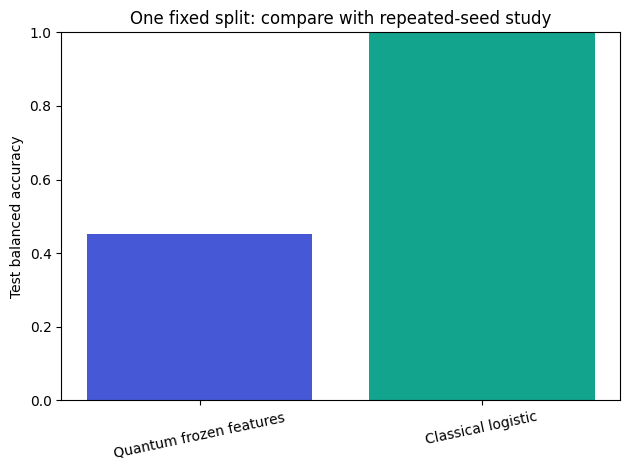

{
  "state_preparations": 96,
  "measurement_shots": 0,
  "kernel_pair_evaluations": 0,
  "warm_start_state_preparations": 0,
  "training_seconds": 0.9119980999967083,
  "statevector_bytes": 64,
  "state_preparations_meaning": "native simulator executions, not hardware state copies",
  "full_density_teacher": false,
  "density_embedding_bytes": 0,
  "simulator_only": true,
  "data_access": "classical feature vectors or known simulator preparation descriptions"
}


In [4]:
plt.bar(list(reports), [r["balanced_accuracy"] for r in reports.values()], color=["#4658d6", "#12a48d"])
plt.ylim(0,1); plt.ylabel("Test balanced accuracy"); plt.title("One fixed split: compare with repeated-seed study")
plt.xticks(rotation=12); plt.tight_layout(); plt.show()
print(json.dumps(quantum.resources_, indent=2))


## 4. Save, reload, and decide what to try next

A classical model may win; report that result. For stronger conclusions run the real-data study with validation tuning and repeated seeds. Change the CSV input only after checking group/time leakage. Load only model artifacts you trust.

In [5]:
path = ARTIFACTS / "wine_frozen_features.joblib"
quantum.save(path)
restored = QMLModel.load(path)
assert np.array_equal(restored.predict(X[test]), quantum.predict(X[test]))
(ARTIFACTS / "classification.json").write_text(json.dumps(reports, indent=2))
print("Saved:", path)


Saved: results\local\notebooks\wine_frozen_features.joblib
